# 05 · Circuit complexity on FakeKingston

Cost of the full protocol circuit (state preparation, Bell pair, measurement unitary, readout) for
both decompositions:

* **all-to-all** – compiled to $\{R_z,\sqrt X,X,\mathrm{CZ}\}$ with no connectivity constraint,
* **FakeKingston** – compiled onto the heavy-hex coupling map with the fixed layout used in the
  experiments (routing adds SWAPs, i.e. extra CZ gates).

Reported: two-qubit gates, single-qubit gates, depth, two-qubit depth, scheduled duration, and the
routing overhead. The QSD reference curve is $\tfrac{23}{48}4^{n}-\tfrac32 2^{n}+\tfrac43$ CNOTs for an
$n=k+1$ qubit unitary (Shende–Bullock–Markov).

In [1]:
# Load the shared settings and functions (00_core.ipynb must be in the same folder)
%run ./00_core.ipynb

FakeKingston: 156 qubits, native gates ['cz', 'delay', 'id', 'if_else', 'measure', 'measure_2', 'reset', 'rz', 'sx', 'x']
core loaded


In [2]:
NATIVE_1Q = ("rz", "sx", "x")

def circuit_metrics(qc):
    # Gate counts and timing of a compiled circuit (barriers and measurements excluded).
    ops = qc.count_ops()
    two_q = sum(n for g, n in ops.items() if g in ("cz", "cx", "ecr"))
    one_q = sum(n for g, n in ops.items() if g in NATIVE_1Q)
    depth_2q = qc.depth(lambda inst: inst.operation.num_qubits == 2)
    return dict(two_q=two_q, one_q=one_q, depth=qc.depth(), depth_2q=depth_2q)


def complexity_m1(k, method):
    # Full m = 1 teleportation circuit (Bob read in Z).
    qc = single_qubit_circuits(k, method, in_state="+")[0]["Z"]
    a2a = transpile(qc, basis_gates=["rz", "sx", "x", "cz"], optimization_level=3,
                    seed_transpiler=SEED)
    dev = transpile(qc, backend=FAKE, initial_layout=LAYOUT_1[k], optimization_level=3,
                    seed_transpiler=SEED)
    out = {"a2a": circuit_metrics(a2a), "dev": circuit_metrics(dev)}
    out["dev"]["duration_us"] = dev.estimate_duration(FAKE.target, unit="s") * 1e6
    return out


cx = {}
print(f"{'k':>2} {'method':<9} | {'2Q a2a':>7} {'2Q dev':>7} {'routing x':>9} | "
      f"{'1Q dev':>7} {'depth':>7} {'2Q depth':>8} {'t (us)':>8}")
print("-" * 78)
for k in KS:
    for method in METHODS:
        cx[(k, method)] = c = complexity_m1(k, method)
        ratio = c["dev"]["two_q"] / max(c["a2a"]["two_q"], 1)
        print(f"{k:>2} {method:<9} | {c['a2a']['two_q']:>7} {c['dev']['two_q']:>7} {ratio:>9.2f} | "
              f"{c['dev']['one_q']:>7} {c['dev']['depth']:>7} {c['dev']['depth_2q']:>8} "
              f"{c['dev']['duration_us']:>8.1f}")

 k method    |  2Q a2a  2Q dev routing x |  1Q dev   depth 2Q depth   t (us)
------------------------------------------------------------------------------
 1 qsd       |       3       3      1.00 |      28      20        3      2.7
 1 isometry  |       3       3      1.00 |      21      17        3      2.7
 2 qsd       |      20      28      1.40 |     162     116       28      5.6
 2 isometry  |      11      16      1.45 |      86      65       16      4.2
 3 qsd       |      96     138      1.44 |     827     576      138     18.8
 3 isometry  |      56      76      1.36 |     362     318       76     11.6
 4 qsd       |     424     671      1.58 |    3598    2538      647     77.3
 4 isometry  |     121     208      1.72 |     852     665      182     23.0
 5 qsd       |    1784    3050      1.71 |   15698   11121     2877    334.6
 5 isometry  |     529    1084      2.05 |    3984    2963      882     98.1


## Two-qubit programs ($m=2$, isometry)

Two measurement blocks plus the program between Bob's qubits; compiled with
`LAYOUT_1[k] + LAYOUT_2[k]`.

In [3]:
cx_2q = {}
print(f"{'k':>2} {'program':<5} | {'2Q dev':>7} {'1Q dev':>7} {'depth':>7} {'t (us)':>8}")
print("-" * 46)
for k in (1, 2, 3, 4):
    for prog, inputs in (("Bell", ("0", "0")), ("SWAP", ("0", "1"))):
        qc, R = two_qubit_circuit(k, "isometry", prog, inputs)
        dev = transpile(qc, backend=FAKE, initial_layout=LAYOUT_1[k] + LAYOUT_2[k],
                        optimization_level=3, seed_transpiler=SEED)
        m = circuit_metrics(dev)
        m["duration_us"] = dev.estimate_duration(FAKE.target, unit="s") * 1e6
        cx_2q[(k, prog)] = m
        print(f"{k:>2} {prog:<5} | {m['two_q']:>7} {m['one_q']:>7} {m['depth']:>7} {m['duration_us']:>8.1f}")

 k program |  2Q dev  1Q dev   depth   t (us)
----------------------------------------------
 1 Bell  |       8      54      19      2.8
 1 SWAP  |       6      46      17      2.7
 2 Bell  |      37     186      75      4.6
 2 SWAP  |      35     178      74      4.5
 3 Bell  |     184     782     334     13.3
 3 SWAP  |     182     780     335     13.3
 4 Bell  |     510    1898     706     27.8
 4 SWAP  |     508    1901     706     27.7


## Complexity figure

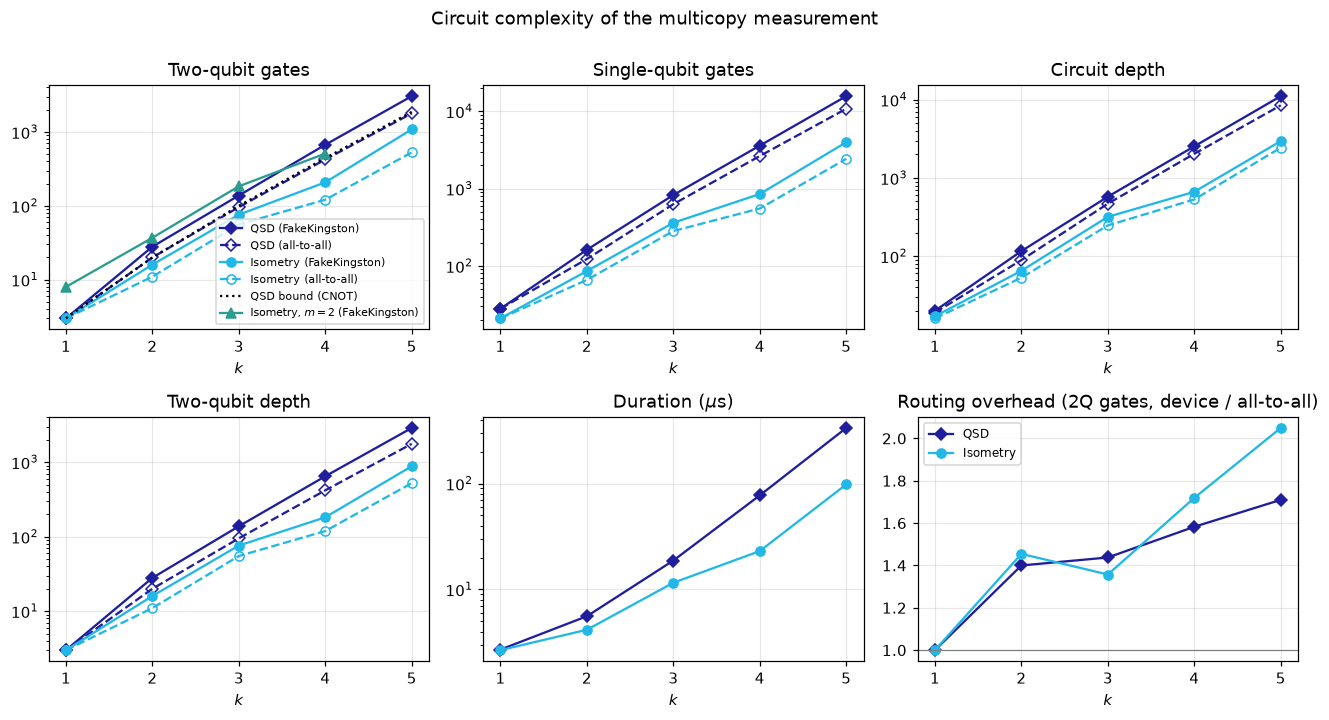

In [4]:
ks = np.array(KS)
n = ks + 1
qsd_bound = 23 / 48 * 4.0 ** n - 1.5 * 2.0 ** n + 4 / 3       # exact QSD CNOT count

fig, ax = plt.subplots(2, 3, figsize=(12, 6.5))
panels = [
    (ax[0, 0], "two_q", "Two-qubit gates", True),
    (ax[0, 1], "one_q", "Single-qubit gates", True),
    (ax[0, 2], "depth", "Circuit depth", True),
    (ax[1, 0], "depth_2q", "Two-qubit depth", True),
    (ax[1, 1], "duration_us", r"Duration ($\mu$s)", True),
]
for a, key, title, logy in panels:
    for method, st in METHOD_STYLE.items():
        a.plot(ks, [cx[(k, method)]["dev"][key] for k in KS], marker=st["marker"],
               color=st["color"], label=f"{st['label']} (FakeKingston)")
        if key != "duration_us":
            a.plot(ks, [cx[(k, method)]["a2a"][key] for k in KS], marker=st["marker"],
                   color=st["color"], ls="--", mfc="none", label=f"{st['label']} (all-to-all)")
    a.set(title=title, xlabel="$k$", xticks=KS)
    if logy:
        a.set_yscale("log")
ax[0, 0].plot(ks, qsd_bound, ":", color="k", label="QSD bound (CNOT)")
ax[0, 0].plot((1, 2, 3, 4), [cx_2q[(k, "Bell")]["two_q"] for k in (1, 2, 3, 4)],
              "^-", color="#2a9d8f", label="Isometry, $m=2$ (FakeKingston)")
ax[0, 0].legend(fontsize=7, loc="lower right")

# routing overhead: two-qubit gates on hardware / all-to-all
a = ax[1, 2]
for method, st in METHOD_STYLE.items():
    a.plot(ks, [cx[(k, method)]["dev"]["two_q"] / max(cx[(k, method)]["a2a"]["two_q"], 1) for k in KS],
           marker=st["marker"], color=st["color"], label=st["label"])
a.axhline(1, color="grey", lw=0.8)
a.set(title="Routing overhead (2Q gates, device / all-to-all)", xlabel="$k$", xticks=KS)
a.legend()

fig.suptitle("Circuit complexity of the multicopy measurement", y=1.0)
fig.tight_layout()
plt.show()

## Gate budget

A rough estimate of where each decomposition stops being useful: the expected fraction of shots without a
two-qubit error is $\approx(1-\epsilon_{2q})^{N_{2q}}$ with the median CZ error of the layout.

In [5]:
qubits = LAYOUT_1[max(KS)]
cz_errs = [FAKE.target["cz"][edge].error for edge in FAKE.target["cz"]
           if edge[0] in qubits and edge[1] in qubits]
eps = float(np.median(cz_errs))
print(f"median CZ error on the layout: {eps:.2e}")
print(f"{'k':>2} | " + " ".join(f"{m:>14}" for m in METHODS))
for k in KS:
    print(f"{k:>2} | " + " ".join(f"{(1 - eps) ** cx[(k, m)]['dev']['two_q']:>14.3f}" for m in METHODS))

median CZ error on the layout: 1.77e-03
 k |            qsd       isometry
 1 |          0.995          0.995
 2 |          0.952          0.972
 3 |          0.783          0.874
 4 |          0.305          0.692
 5 |          0.005          0.147
